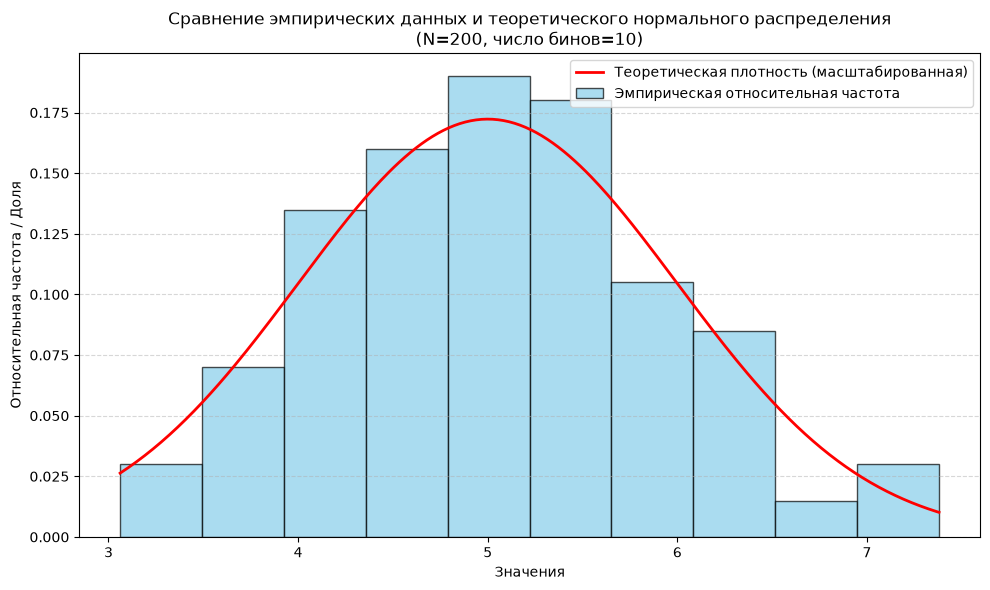

Число отрезков N = 10
Ширина отрезка = 0.4319
----------------------------------------
Центр      | Отн. частота    | Теор. доля
3.277      | 0.0300          | 0.0391    
3.709      | 0.0700          | 0.0751    
4.141      | 0.1350          | 0.1195    
4.573      | 0.1600          | 0.1576    
5.005      | 0.1900          | 0.1723    
5.437      | 0.1800          | 0.1571    
5.869      | 0.1050          | 0.1187    
6.300      | 0.0850          | 0.0743    
6.732      | 0.0150          | 0.0386    
7.164      | 0.0300          | 0.0166    


In [1]:
from random import random
import matplotlib.pyplot as plt
import math
import numpy as np

# --- Параметры ---
m = 5
sigma = 1
n = 200
N_bins = 2*int(math.log(n))  # N = 2*[log(200)] = 2*5=10

# --- 1. Генерация данных (исправленная) ---
numbers = []
for _ in range(n):
    x = 0
    for _ in range(12):
        x += random()
    x -= 6  # Центрирование суммы 12 равномерных величин
    numbers.append(sigma * x + m)

# --- 2. Разбиение на отрезки и подсчет частот ---
min_val = min(numbers)
max_val = max(numbers)
bin_width = (max_val - min_val) / N_bins

# Границы отрезков
bin_edges = [min_val + i * bin_width for i in range(N_bins + 1)]

# Подсчет попаданий
counts = [0] * N_bins
for val in numbers:
    idx = int((val - min_val) / bin_width)
    if idx >= N_bins:
        idx = N_bins - 1
    counts[idx] += 1

# Относительные частоты (доля от общего числа)
rel_freq = [c / n for c in counts]

# Середины отрезков для графика
bin_centers = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in range(N_bins)]

# --- 3. Теоретическая кривая (Нормальное распределение) ---
# Создаем плавный массив точек для построения линии
x_theory = np.linspace(min_val, max_val, 300)

# Функция плотности нормального распределения
def normal_pdf(x, mu, sigma):
    return (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)

y_theory_pdf = normal_pdf(x_theory, m, sigma)

# ВАЖНО: 
# rel_freq — это доля значений в бине (сумма = 1).
# PDF интегрируется в 1. 
# Чтобы сравнить высоту столбца (доля) с кривой, нужно умножить PDF на ширину бина.
# Тогда значение кривой покажет "ожидаемую долю" в данном интервале.
y_theory_scaled = y_theory_pdf * bin_width

# --- 4. Построение графика ---
plt.figure(figsize=(10, 6))

# Столбчатая диаграмма (эмпирические данные)
plt.bar(bin_centers, rel_freq, width=bin_width, color='skyblue', edgecolor='black', alpha=0.7, label='Эмпирическая относительная частота')

# Теоретическая кривая
plt.plot(x_theory, y_theory_scaled, color='red', linewidth=2, label='Теоретическая плотность (масштабированная)')

plt.xlabel("Значения")
plt.ylabel("Относительная частота / Доля")
plt.title(f"Сравнение эмпирических данных и теоретического нормального распределения\n(N={n}, число бинов={N_bins})")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Вывод таблицы для проверки
print(f"Число отрезков N = {N_bins}")
print(f"Ширина отрезка = {bin_width:.4f}")
print("-" * 40)
print(f"{'Центр':<10} | {'Отн. частота':<15} | {'Теор. доля':<10}")
for i in range(N_bins):
    print(f"{bin_centers[i]:<10.3f} | {rel_freq[i]:<15.4f} | {y_theory_scaled[np.argmin(np.abs(x_theory - bin_centers[i]))]:<10.4f}")